In [1]:
### standard libraries
import numpy as np
import matplotlib.pyplot as plt

### other libraries
import finufft

### my modules
from fast_volume_align_ot import utils, plots, transforms

In [15]:
def pdf_tensor_to_cdf_tensor(F):
   
    ### EV: will need to add a normalization step for doing the signed distance

    return np.cumsum(F, axis=1)


def cdf_tensor_to_icdf_tensor(C):
    
    U = np.zeros(C.shape)
    n_phi, nx, n_theta = C.shape
     
    ### EV: add option later to change number of points and spacing if desired
    x = np.linspace(0, 1, nx, endpoint=True)
    
    ### EV: NEED TO VECTORIZE THIS
    for phi in range(n_phi):
        for theta in range(n_theta):
            U[phi, :, theta] = np.interp(x, C[phi, :, theta], x)
    
    ### EV: ENFORCE BOUNDS (not sure why this helps)
    U[:, 0, :] = 0
    U[:, -1, :] = 1

    return U

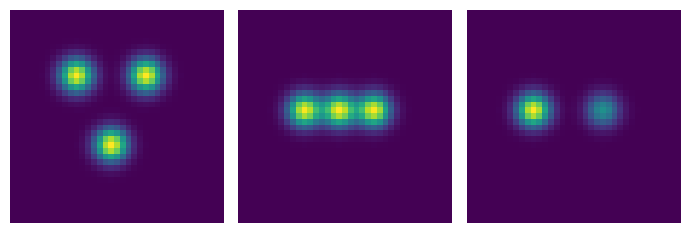

In [2]:
### generate initial volume
L = 37
sigma = 2
f = utils.generate_3d_triangle_gaussian_shape(L, sigma)
# f = utils.generate_centered_gaussian(L=L, d=3, sigma=sigma)

# ### zero pad to allow for shifting
# w = 15
# f = np.pad(f, pad_width=((w, w), (w, w), (w, w)))
# print(f.shape)

plots.orthogonal_2D_projection_plot(f)

In [3]:
F = transforms.compute_projection_tensor_from_voxel_array(f)

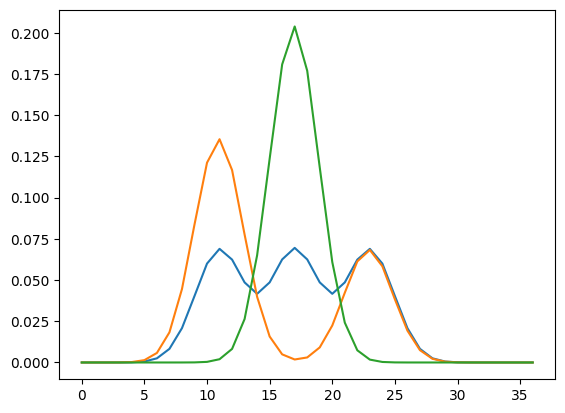

In [14]:
o1 = F[0, :, 0]
o2 = F[9, :, 9]
o3 = F[0, :, 9]

plt.plot(o1)
plt.plot(o2)
plt.plot(o3)

In [9]:
F_cdf = np.cumsum(F, axis=1)

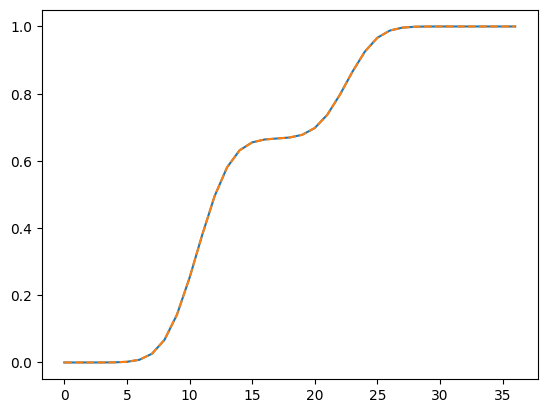

In [13]:
plt.plot(np.cumsum(F[9, :, 10]))
plt.plot(F_cdf[9, :, 10], '--')

In [26]:
# A = np.arange(4*4).reshape(4,4)
# A = np.ones((2, 4, 4)) * A

# for a, b in enumerate(A):
#     for c, d in enumerate(b):
#         print(d)

In [46]:
C = pdf_tensor_to_cdf_tensor(F)

U = cdf_tensor_to_icdf_tensor(C)

In [33]:
n_phi, nx, n_theta = C.shape

U = np.zeros(C.shape)

### EV: add option later to change number of points and spacing if desired
x = np.linspace(0, 1, nx, endpoint=True)

### EV: NEED TO VECTORIZE THIS
for phi in range(n_phi):
    for theta in range(n_theta):
        U[phi, :, theta] = np.interp(x, C[phi, :, theta], x)

### EV: ENFORCE BOUNDS (not sure why this helps)
U[:, 0, :] = 0
U[:, -1, :] = 1

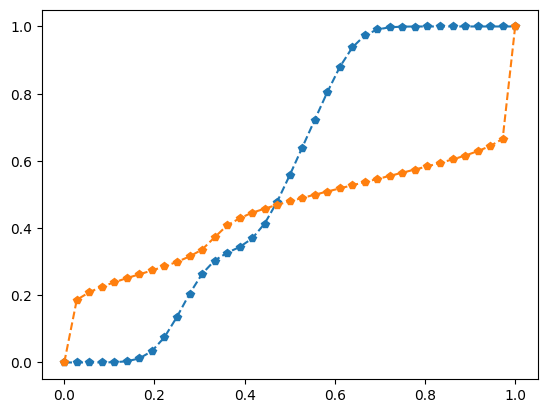

In [44]:
phi_idx, theta_idx = 10, 1
plt.plot(x, C[phi_idx, :, theta_idx], 'p--')
plt.plot(x, U[phi_idx, :, theta_idx], 'p--')

In [34]:
# def get_uniform_inverse_cdf(self, images_cdf):
    
#     images_icdf = np.zeros(images_cdf.shape)
    
#     x = np.linspace(0, 1, self.n_points, endpoint=True)  # EV: use this in interp if including different amount of sampling (xp)
#     xp = np.linspace(0, 1, self.n_points, endpoint=True)  # EV: make uniform grid from [0, 1] for interpolation
            
#     for n, cdfs in enumerate(images_cdf):
        
#         for idx in range(self.n_lines):
            
#             icdf = np.interp(x, cdfs[:, idx], xp)
                            
#             ### EV: HACK TO ENFORCE BOUNDS (not sure why this helps)
#             icdf[0] = 0
#             icdf[-1] = 1
#             ###
            
#             images_icdf[n, :, idx] = icdf
            
#     return images_icdf